# LAB 1

In [85]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [86]:
# Load data
df = pd.read_csv('/content/drive/MyDrive/Iris new.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [88]:
# Features Selection
X = df.iloc[:, 1:-1] # slice the features
y = df.iloc[:, -1] # this is the labels (we don't need it)

In [89]:
print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


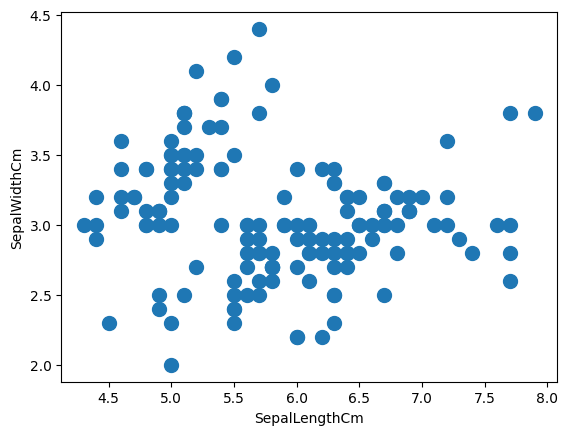

In [90]:
# Make a scatterplot using
# SepalLengthCm and SepalWidthCm
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

In [91]:
# Build a K-Means Model
# Based on visual inspection using scatterplot,
# we can assumpt that the data has 2 cluster
# (even though, from the label, there are 3 labels in this data)

from sklearn.cluster import KMeans

# Initiate K-Means object with numbur of cluster is 2
cl_kmeans = KMeans(n_clusters=2)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

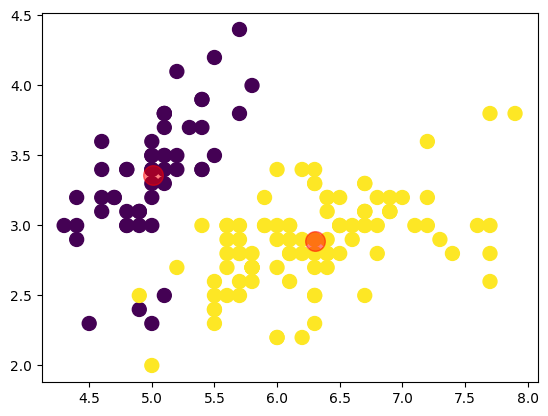

In [92]:
# Plot the clustering result
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot the centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [93]:
# Evaluasi model
# Print SSE value
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


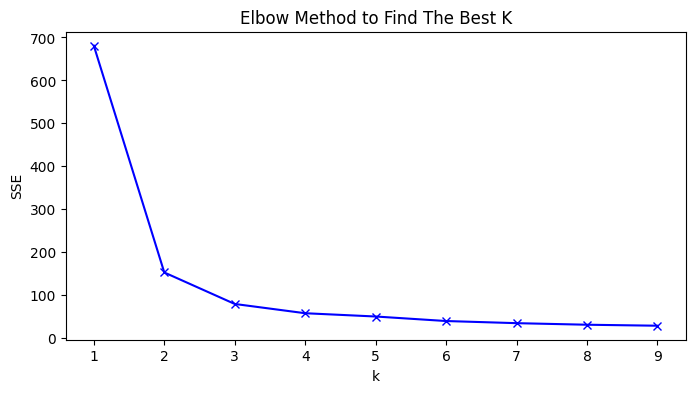

In [94]:
# Menentukan K terbaik dengan elbow method

# Find the best k
# using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 9
K = range(1,10)

# Find the SSE value for each k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

# LAB 2

In [95]:
# Import Library
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [96]:
# Membuat Dataset Sintentis
from sklearn.datasets import make_moons

X, y = make_moons(200, noise=.05, random_state=0)

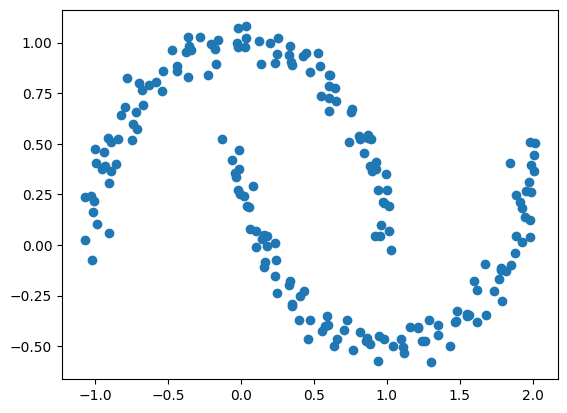

In [97]:
# Plotting data
plt.scatter(X[:, 0], X[:, 1])

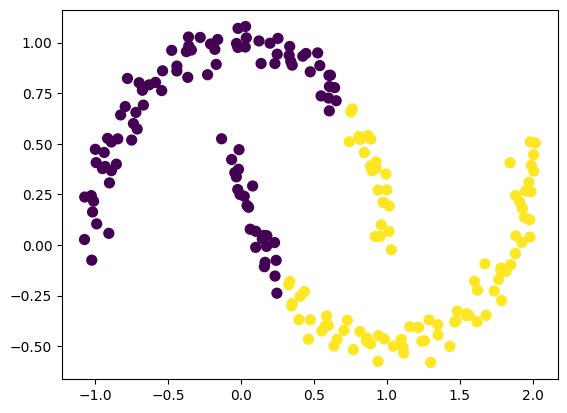

In [98]:
# Klasterisasi dengan K-Means
from sklearn.cluster import KMeans

kmeans = KMeans(2, random_state=0)
cluster = kmeans.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=cluster, s=50, cmap='viridis')

In [99]:
# Lakukan evaluasi lebih lanjut dengan menggunakan silhouette coefficient.
from sklearn.metrics import silhouette_score

print(silhouette_score(X, cluster))

0.49215648268306905


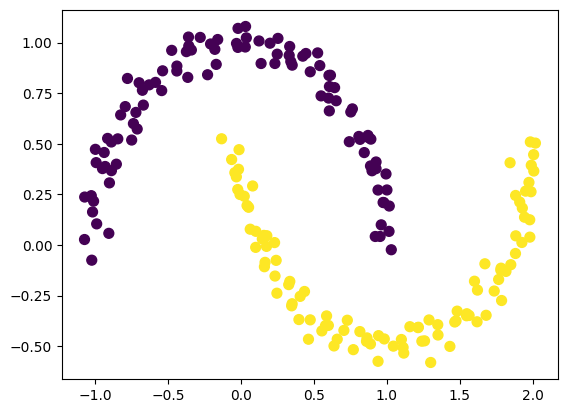

In [100]:
# Klasterisasi dengan DBSCAN
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.3, min_samples=2)
cluster_db = dbscan.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=cluster_db, s=50, cmap='viridis')

In [101]:
# evaluasi kembali dengan silhouette score.
from sklearn.metrics import silhouette_score

print(silhouette_score(X, cluster_db))

# Hasil 0.32585318950197517

0.32585318950197517


In [102]:
# Davies-Bouldin Index (DBI) --> fokus pada separasi indeks, semakin kecil semakin baik, rentang 0 hingga tak hingga.
from sklearn.metrics import davies_bouldin_score

# Compute and print Davies-Bouldin Index
db = davies_bouldin_score(X, cluster_db)

print(f"Davies-Bouldin Index: {db}")

# Hasilnya
# Davies-Bouldin Index: 1.1622685374061352

Davies-Bouldin Index: 1.1622685374061352


# LAB 3

In [103]:
# Import library
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

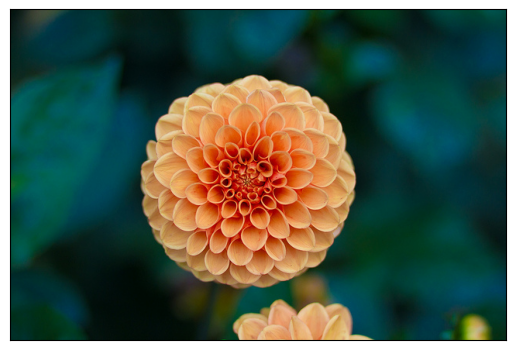

In [104]:
# Load data citra
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)

In [105]:
# Preprocessing
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3) # turn to 1D

print(data.shape)

(427, 640, 3)
(273280, 3)


In [106]:
# Cek Sebaran Warna
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

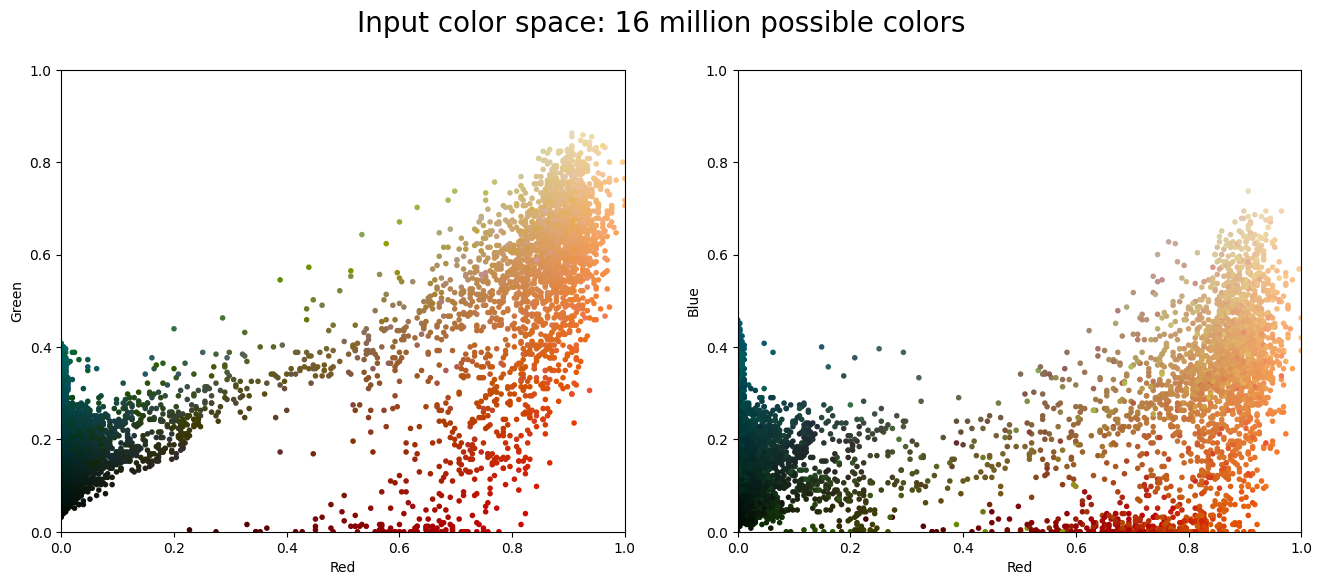

In [107]:
# Panggil function
plot_pixels(data, title='Input color space: 16 million possible colors')

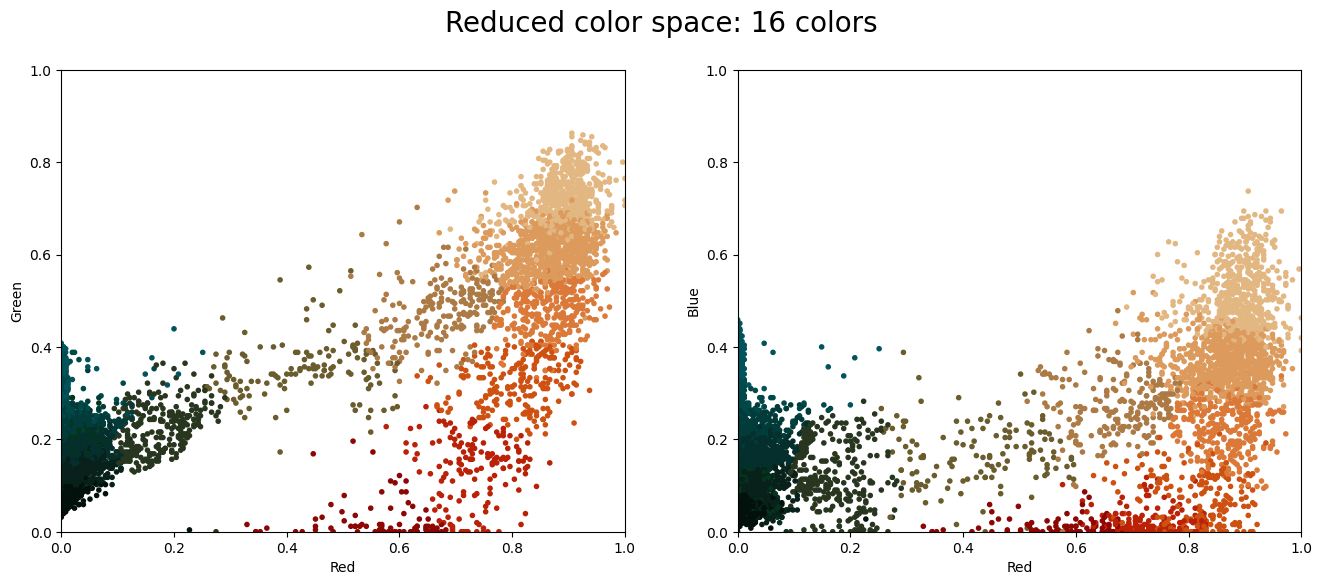

In [108]:
# Klasterisasi Warna
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

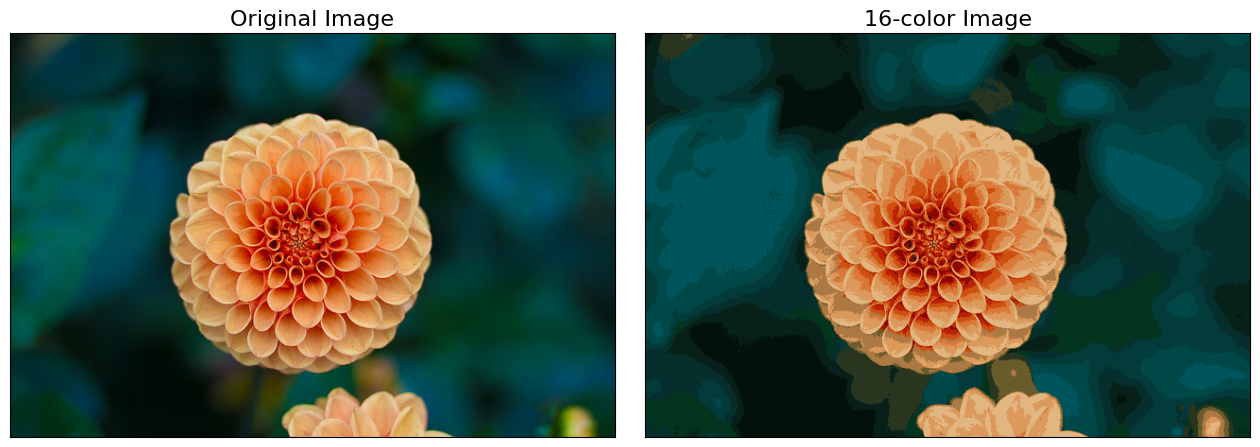

In [109]:
# Hasil perbandingan warna citra sebelum dan setelah kompresi adalah sebagai berikut

flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

# TUGAS LAB

In [110]:
# Analisis klasterisasi CC_Customer_Dataset: K-Means & DBSCAN

# Import Library
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [111]:
# Load data
df = pd.read_csv('/content/drive/MyDrive/CC_Customer_Dataset.csv')
x, y = 'Avg_Credit_Limit', 'Total_Credit_Cards'

Pearson: 0.6088604935524955


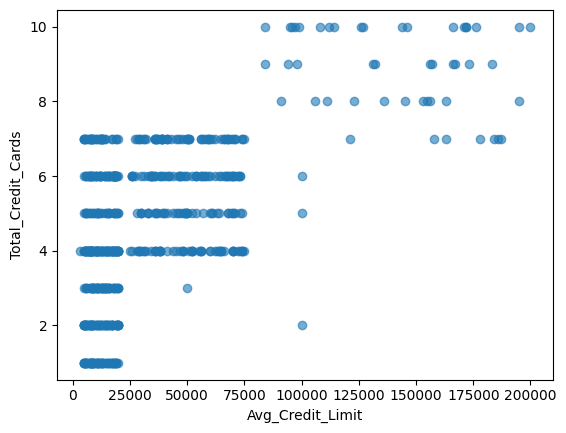

In [112]:
# 1. Scatterplot + uji linieritas
print('Pearson:', df[[x, y]].corr().iloc[0, 1])
plt.scatter(df[x], df[y], alpha=.6); plt.xlabel(x); plt.ylabel(y); plt.show()

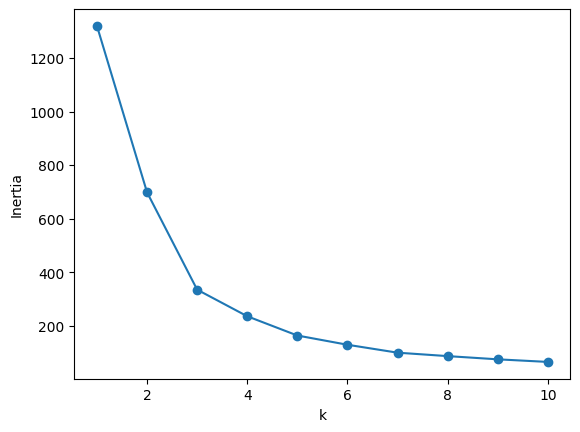

In [113]:
# 2. Elbow K-Means (data distandardisasi)
X2 = StandardScaler().fit_transform(df[[x, y]])
inertia = [KMeans(k, n_init=10, random_state=42).fit(X2).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.show()

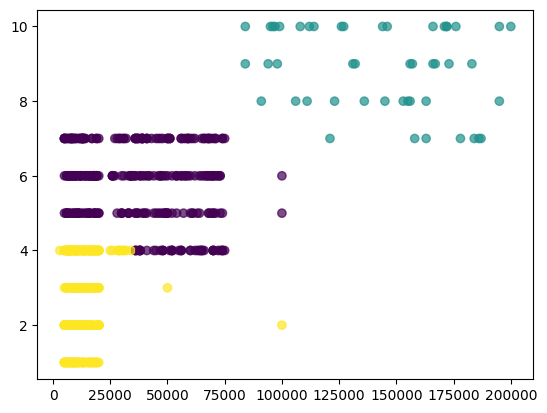

In [114]:
# 3. K-Means k=3
km = KMeans(3, n_init=10, random_state=42).fit(X2)
plt.scatter(df[x], df[y], c=km.labels_, cmap='viridis', alpha=.7); plt.show()

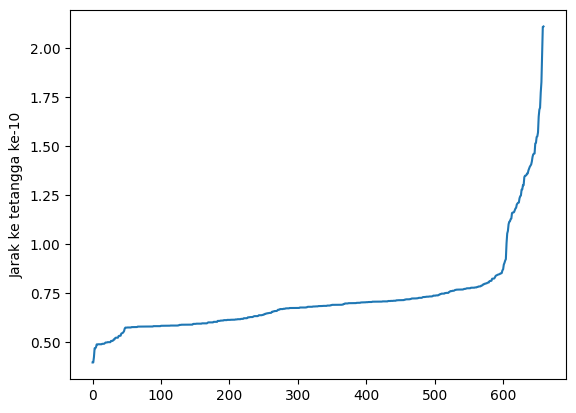

In [115]:
# 4-5. DBSCAN: semua variabel numerik selain ID (Sl_No, Customer Key)
feats = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
         'Total_visits_online', 'Total_calls_made']
XS = StandardScaler().fit_transform(df[feats])
minpts = 2 * len(feats)                                   # 10
kdist = np.sort(NearestNeighbors(n_neighbors=minpts).fit(XS).kneighbors(XS)[0][:, -1])
plt.plot(kdist); plt.ylabel(f'Jarak ke tetangga ke-{minpts}'); plt.show()
eps = 1.46                                                # titik siku pada k-distance plot
labels = DBSCAN(eps=eps, min_samples=minpts).fit_predict(XS)

In [116]:
# 6. Evaluasi (tanpa titik noise)
mask = labels != -1
print('Silhouette:', silhouette_score(XS[mask], labels[mask]))
print('DBI       :', davies_bouldin_score(XS[mask], labels[mask]))

Silhouette: 0.5747777459808416
DBI       : 0.6242306972235019
